In [1]:
from google.colab import drive
drive.mount('/content/drive')

zip_path = '/content/drive/MyDrive/Faks/3. semestar-DRB/Duboko učenje/LV2_Kocis/iris_pupil_eye.zip'

extract_path = '/content/dataset'

import os
os.makedirs(extract_path, exist_ok=True)

print("Otpakiravanje u tijeku...")
!unzip -q "{zip_path}" -d "{extract_path}"
print("Dataset je uspješno otpakiran na lokalni disk Colaba!")

Mounted at /content/drive
Otpakiravanje u tijeku...
Dataset je uspješno otpakiran na lokalni disk Colaba!


In [2]:
!pip install -q segmentation-models-pytorch

In [3]:
import os
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

# Definiranje osnovne putanje prema strukturi sa slike
base_path = '/content/dataset/iris_pupil_eye'
splits = ['train', 'val', 'test']

print("=== 1. ANALIZA BROJA SLIKA I REZOLUCIJA ===")
for split in splits:
    img_dir = os.path.join(base_path, split, 'images')
    mask_dir = os.path.join(base_path, split, 'masks')

    if os.path.exists(img_dir):
        images = sorted([f for f in os.listdir(img_dir) if f.endswith(('.png', '.jpg', '.jpeg'))])
        print(f"Skup '{split}': {len(images)} slika")

        # Provjera rezolucije prve slike u skupu
        if len(images) > 0:
            sample_img_path = os.path.join(img_dir, images[0])
            with Image.open(sample_img_path) as img:
                print(f"   -> Primjer rezolucije ({images[0]}): {img.size} (Š x V), Format: {img.format}")
    else:
        print(f"Skup '{split}' ne postoji ili je putanja kriva ({img_dir}).")

print("\n=== 2. ANALIZA DISTRIBUCIJE KLASA (TRAIN SKUP) ===")
# Klase: 0 = pozadina, 1 = zjenica, 2 = šarenica, 3 = bjeloočnica
train_mask_dir = os.path.join(base_path, 'train', 'masks')

if os.path.exists(train_mask_dir):
    class_pixels = {0: 0, 1: 0, 2: 0, 3: 0}
    mask_files = [f for f in os.listdir(train_mask_dir) if f.endswith(('.png', '.jpg', '.jpeg'))]

    for mask_name in mask_files:
        mask_path = os.path.join(train_mask_dir, mask_name)
        mask = np.array(Image.open(mask_path))

        # Prebrojavanje piksela za svaku klasu
        unique, counts = np.unique(mask, return_counts=True)
        for u, c in zip(unique, counts):
            if u in class_pixels:
                class_pixels[u] += c

    total_pixels = sum(class_pixels.values())
    class_names = {
        0: "Pozadina (0)",
        1: "Zjenica (1)",
        2: "Šarenica (2)",
        3: "Bjeloočnica (3)"
    }

    print("Ukupna zastupljenost piksela po klasama u trening skupu:")
    for cls_id, name in class_names.items():
        pixels = class_pixels[cls_id]
        percentage = (pixels / total_pixels) * 100 if total_pixels > 0 else 0
        print(f" - {name}: {pixels:,} piksela ({percentage:.2f}%)")
else:
    print("Train mask folder ne postoji za analizu klasa.")

=== 1. ANALIZA BROJA SLIKA I REZOLUCIJA ===
Skup 'train': 800 slika
   -> Primjer rezolucije (0213_2_1_2_53_006.png): (640, 480) (Š x V), Format: PNG
Skup 'val': 200 slika
   -> Primjer rezolucije (0214_1_1_2_20_003.png): (640, 480) (Š x V), Format: PNG
Skup 'test': 275 slika
   -> Primjer rezolucije (0193_1_1_2_33_000.png): (640, 480) (Š x V), Format: PNG

=== 2. ANALIZA DISTRIBUCIJE KLASA (TRAIN SKUP) ===
Ukupna zastupljenost piksela po klasama u trening skupu:
 - Pozadina (0): 167,522,569 piksela (68.17%)
 - Zjenica (1): 43,042,330 piksela (17.51%)
 - Šarenica (2): 11,768,681 piksela (4.79%)
 - Bjeloočnica (3): 23,426,420 piksela (9.53%)


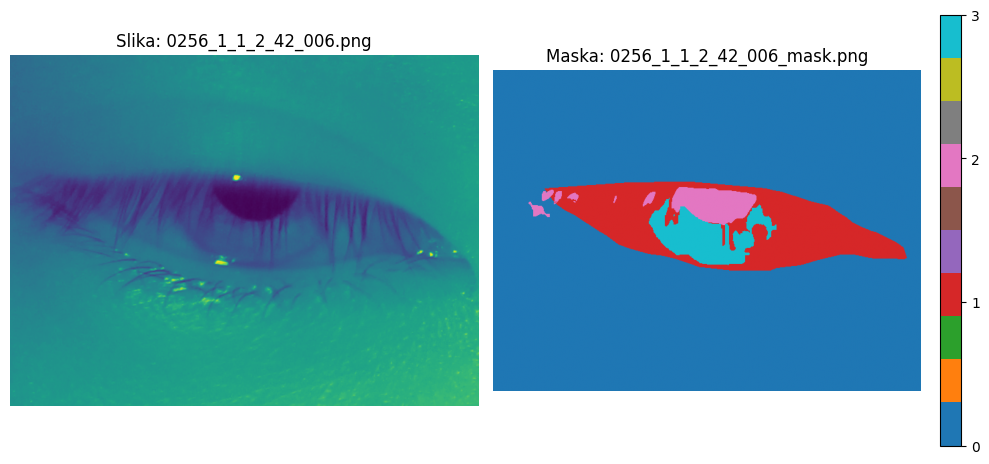

In [4]:
import os
import random
from PIL import Image
import matplotlib.pyplot as plt

base_path = '/content/dataset/iris_pupil_eye'
train_img_dir = os.path.join(base_path, 'train', 'images')
train_mask_dir = os.path.join(base_path, 'train', 'masks')

if os.path.exists(train_img_dir) and os.path.exists(train_mask_dir):
    # Dohvaćamo sortirane liste slika i maski
    images_list = sorted([f for f in os.listdir(train_img_dir) if f.endswith(('.png', '.jpg', '.jpeg'))])
    masks_list = sorted([f for f in os.listdir(train_mask_dir) if f.endswith(('.png', '.jpg', '.jpeg'))])

    if len(images_list) > 0 and len(masks_list) > 0:
        # Biramo nasumični indeks
        idx = random.randint(0, len(images_list) - 1)

        img_name = images_list[idx]
        mask_name = masks_list[idx]

        img_path = os.path.join(train_img_dir, img_name)
        mask_path = os.path.join(train_mask_dir, mask_name)

        img = Image.open(img_path)
        mask = Image.open(mask_path)

        # Prikaz
        fig, axes = plt.subplots(1, 2, figsize=(10, 5))
        axes[0].imshow(img)
        axes[0].set_title(f"Slika: {img_name}")
        axes[0].axis('off')

        # Prikaz maske s paletom boja za 4 klase (0, 1, 2, 3)
        im_mask = axes[1].imshow(mask, cmap='tab10', vmin=0, vmax=3)
        axes[1].set_title(f"Maska: {mask_name}")
        axes[1].axis('off')
        fig.colorbar(im_mask, ax=axes[1], ticks=[0, 1, 2, 3], fraction=0.046, pad=0.04)

        plt.tight_layout()
        plt.show()
    else:
        print("Mape su prazne.")
else:
    print("Putanja do mapa ne postoji.")

In [6]:
import os
from PIL import Image
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
import albumentations as A

class EyeSegmentationDataset(Dataset):
    def __init__(self, image_dir, mask_dir, transform=None):
        self.image_dir = image_dir
        self.mask_dir = mask_dir
        self.transform = transform

        # Dohvaćamo i sortiramo liste iz oba direktorija nezavisno
        self.images = sorted([f for f in os.listdir(image_dir) if f.endswith(('.png', '.jpg', '.jpeg'))])
        self.masks = sorted([f for f in os.listdir(mask_dir) if f.endswith(('.png', '.jpg', '.jpeg'))])

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img_name = self.images[idx]
        mask_name = self.masks[idx]

        img_path = os.path.join(self.image_dir, img_name)
        mask_path = os.path.join(self.mask_dir, mask_name)

        # Učitavanje RGB slike i maske kao NumPy polja (obavezno za Albumentations)
        image = np.array(Image.open(img_path).convert("RGB"), dtype=np.uint8)
        mask = np.array(Image.open(mask_path), dtype=np.uint8)

        # Normalizacija slike na [0, 1]
        image = image.astype(np.float32) / 255.0

        # Pretvorba u PyTorch tenzore (slika: [C, H, W], maska: [H, W])
        image = torch.tensor(image).permute(2, 0, 1)
        mask = torch.tensor(mask, dtype=torch.long)

        return image, mask

# 2. Inicijalizacija train i val dataloader-a
TRAIN_IMG_DIR = '/content/dataset/iris_pupil_eye/train/images'
TRAIN_MASK_DIR = '/content/dataset/iris_pupil_eye/train/masks'
VAL_IMG_DIR = '/content/dataset/iris_pupil_eye/val/images'
VAL_MASK_DIR = '/content/dataset/iris_pupil_eye/val/masks'

# Train dataset dobiva augmentacije, dok validacijski ostaje čist (transform=None)
train_dataset = EyeSegmentationDataset(TRAIN_IMG_DIR, TRAIN_MASK_DIR)
train_loader = DataLoader(train_dataset, batch_size=4, shuffle=True, num_workers=2)

val_dataset = EyeSegmentationDataset(VAL_IMG_DIR, VAL_MASK_DIR, transform=None)
val_loader = DataLoader(val_dataset, batch_size=4, shuffle=False, num_workers=2)

print(f"Uspješno Train: {len(train_dataset)}, Val: {len(val_dataset)}")

Uspješno Train: 800, Val: 200


In [7]:
import time
import torch
import torch.nn as nn
import torch.optim as optim
import segmentation_models_pytorch as smp

# 1. Definiranje uređaja
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Koristim uređaj: {DEVICE}")

# 2. Inicijalizacija U-Net modela s ResNet34 enkoderom
NUM_CLASSES = 4 # pozadina, zjenica, šarenica, bjeloočnica
model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights="imagenet",
    in_channels=3,
    classes=NUM_CLASSES,
).to(DEVICE)

# 3. Funkcija gubitka, optimizator i scheduler
criterion = smp.losses.DiceLoss(smp.losses.MULTICLASS_MODE, from_logits=True)
optimizer = optim.Adam(model.parameters(), lr=0.001)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='min', factor=0.1, patience=3)

# 4. Funkcija za treniranje jedne epohe
def train_epoch(model, loader, optimizer, criterion, device):
    model.train()
    running_loss = 0.0
    for images, masks in loader:
        images = images.to(device, dtype=torch.float32)
        masks = masks.to(device, dtype=torch.long)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, masks)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    return running_loss / len(loader)

# 5. Funkcija za evaluaciju (mIoU i mDice)
def evaluate_model(model, loader, device):
    model.eval()
    total_iou = 0.0
    total_dice = 0.0

    with torch.no_grad():
        for images, masks in loader:
            images = images.to(device, dtype=torch.float32)
            masks = masks.to(device, dtype=torch.long)

            outputs = model(images)
            preds = outputs.argmax(dim=1)

            tp, fp, fn, tn = smp.metrics.get_stats(
                preds, masks, mode='multiclass', num_classes=NUM_CLASSES
            )

            # Ispravljeno: "macro-class" promijenjeno u "macro"
            iou = smp.metrics.iou_score(tp, fp, fn, tn, reduction="macro")
            dice = smp.metrics.f1_score(tp, fp, fn, tn, reduction="macro")

            total_iou += iou.item()
            total_dice += dice.item()

    return total_iou / len(loader), total_dice / len(loader)

print("Funkcija za evaluaciju je ispravljena!")

Koristim uređaj: cuda


config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 87.3MB            

model.safetensors: downloading bytes:           |  0.00B            

Funkcija za evaluaciju je ispravljena!


Početak treniranja modela s praćenjem krivulja metrika...
[Epoha 1] Spremljen NAJBOLJI MODEL! (Loss: 0.1916)
Epoha [1/10] (111.6s) | Loss: 0.1916 | mIoU: 0.8481 | mDice: 0.9142
[Epoha 2] Spremljen NAJBOLJI MODEL! (Loss: 0.0786)
Epoha [2/10] (114.2s) | Loss: 0.0786 | mIoU: 0.8652 | mDice: 0.9249
[Epoha 3] Spremljen NAJBOLJI MODEL! (Loss: 0.0669)
Epoha [3/10] (114.3s) | Loss: 0.0669 | mIoU: 0.8902 | mDice: 0.9399
[Epoha 4] Spremljen NAJBOLJI MODEL! (Loss: 0.0648)
Epoha [4/10] (114.2s) | Loss: 0.0648 | mIoU: 0.8806 | mDice: 0.9342
[Epoha 5] Spremljen NAJBOLJI MODEL! (Loss: 0.0634)
Epoha [5/10] (114.3s) | Loss: 0.0634 | mIoU: 0.8005 | mDice: 0.8792
[Epoha 6] Spremljen NAJBOLJI MODEL! (Loss: 0.0600)
Epoha [6/10] (113.9s) | Loss: 0.0600 | mIoU: 0.8968 | mDice: 0.9439
[Epoha 7] Spremljen NAJBOLJI MODEL! (Loss: 0.0571)
Epoha [7/10] (114.0s) | Loss: 0.0571 | mIoU: 0.8959 | mDice: 0.9432
[Epoha 8] Spremljen NAJBOLJI MODEL! (Loss: 0.0552)
Epoha [8/10] (114.4s) | Loss: 0.0552 | mIoU: 0.9055 | mDic

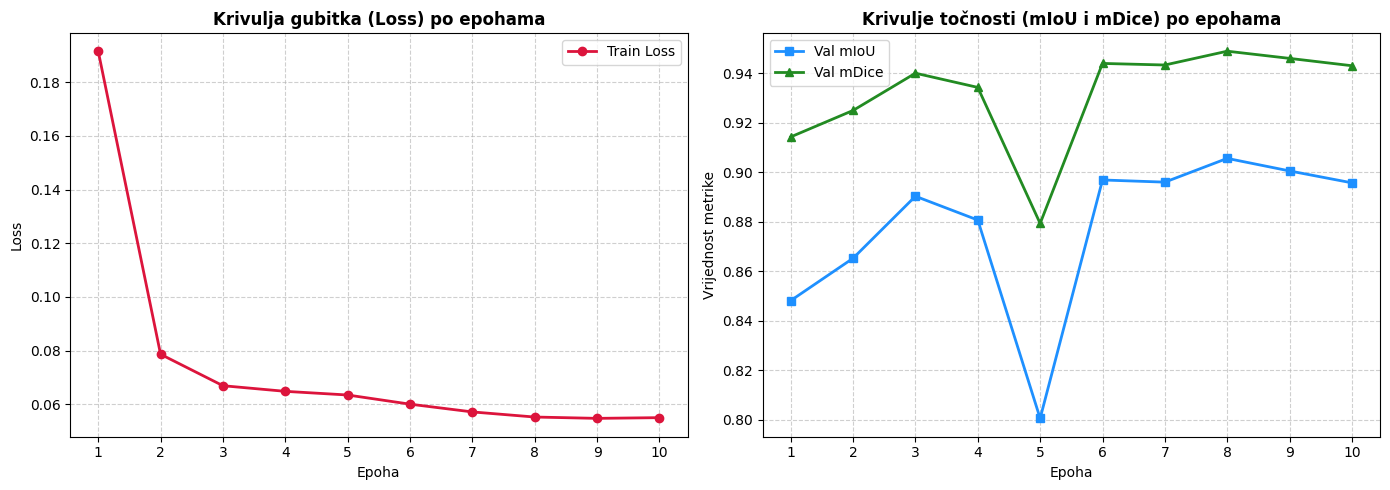

In [8]:
import time
import torch
import matplotlib.pyplot as plt

NUM_EPOCHS = 10
best_loss = float('inf')
best_model_path = '/content/best_unet_eye_model.pth'

# Rječnik za spremanje povijesti metrika po epohama
history = {
    'train_loss': [],
    'val_iou': [],
    'val_dice': []
}

print("Početak treniranja modela s praćenjem krivulja metrika...")
for epoch in range(NUM_EPOCHS):
    start_time = time.time()

    # 1. Treniranje i evaluacija
    loss = train_epoch(model, train_loader, optimizer, criterion, DEVICE)
    iou, dice = evaluate_model(model, val_loader, DEVICE)

    scheduler.step(loss)

    # 2. Spremanje vrijednosti u povijest
    history['train_loss'].append(loss)
    history['val_iou'].append(iou)
    history['val_dice'].append(dice)

    # 3. Spremanje najboljeg modela
    if loss < best_loss:
        best_loss = loss
        torch.save(model.state_dict(), best_model_path)
        print(f"[Epoha {epoch+1}] Spremljen NAJBOLJI MODEL! (Loss: {loss:.4f})")

    epoch_time = time.time() - start_time
    print(f"Epoha [{epoch+1}/{NUM_EPOCHS}] ({epoch_time:.1f}s) | Loss: {loss:.4f} | mIoU: {iou:.4f} | mDice: {dice:.4f}")

print(f"\nTreniranje završeno! Najbolji model je spremljen na: {best_model_path}")

# ==========================================
# 4. ISCRTAVANJE KRIVULJA METRIKA
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Graf 1: Gubitak (Loss)
axes[0].plot(range(1, NUM_EPOCHS + 1), history['train_loss'], marker='o', color='crimson', linewidth=2, label='Train Loss')
axes[0].set_title('Krivulja gubitka (Loss) po epohama', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Epoha')
axes[0].set_ylabel('Loss')
axes[0].set_xticks(range(1, NUM_EPOCHS + 1))
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].legend()

# Graf 2: mIoU i mDice
axes[1].plot(range(1, NUM_EPOCHS + 1), history['val_iou'], marker='s', color='dodgerblue', linewidth=2, label='Val mIoU')
axes[1].plot(range(1, NUM_EPOCHS + 1), history['val_dice'], marker='^', color='forestgreen', linewidth=2, label='Val mDice')
axes[1].set_title('Krivulje točnosti (mIoU i mDice) po epohama', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Epoha')
axes[1].set_ylabel('Vrijednost metrike')
axes[1].set_xticks(range(1, NUM_EPOCHS + 1))
axes[1].grid(True, linestyle='--', alpha=0.6)
axes[1].legend()

plt.tight_layout()
plt.show()

In [9]:
import torch
from torch.utils.data import DataLoader

# Definiraj putanje do testnog skupa (prilagodi ako se direktorij drukčije zove)
TEST_IMG_DIR = '/content/dataset/iris_pupil_eye/test/images'
TEST_MASK_DIR = '/content/dataset/iris_pupil_eye/test/masks'

# Inicijalizacija testnog dataseta (transform=None jer se na testnom skupu ne rade augmentacije!)
test_dataset = EyeSegmentationDataset(TEST_IMG_DIR, TEST_MASK_DIR, transform=None)
test_loader = DataLoader(test_dataset, batch_size=4, shuffle=False, num_workers=2)

print(f"Uspješno učitan testni skup! Broj testnih slika: {len(test_dataset)}")

Uspješno učitan testni skup! Broj testnih slika: 275


In [10]:
import segmentation_models_pytorch as smp

# Učitavanje najboljeg modela (ako već nije učitan)
model.load_state_dict(torch.load('/content/best_unet_eye_model.pth'))
model.to(DEVICE)
model.eval()

class_names = ['Pozadina', 'Zjenica', 'Šarenica', 'Bjeloočnica']
tp_list, fp_list, fn_list, tn_list = [], [], [], []

# Prikupljanje statistike preko cijelog testnog skupa
with torch.no_grad():
    for images, masks in test_loader:
        images = images.to(DEVICE, dtype=torch.float32)
        masks = masks.to(DEVICE, dtype=torch.long)

        outputs = model(images)
        preds = outputs.argmax(dim=1)

        tp, fp, fn, tn = smp.metrics.get_stats(
            preds, masks, mode='multiclass', num_classes=NUM_CLASSES
        )
        tp_list.append(tp)
        fp_list.append(fp)
        fn_list.append(fn)
        tn_list.append(tn)

# Spajanje i sumiranje statistike za testni skup
tp = torch.cat(tp_list).sum(dim=0)
fp = torch.cat(fp_list).sum(dim=0)
fn = torch.cat(fn_list).sum(dim=0)
tn = torch.cat(tn_list).sum(dim=0)

# Izračun ukupnih i pojedinačnih metrika
macro_iou = smp.metrics.iou_score(tp, fp, fn, tn, reduction="macro").item()
macro_dice = smp.metrics.f1_score(tp, fp, fn, tn, reduction="macro").item()

per_class_iou = smp.metrics.iou_score(tp, fp, fn, tn, reduction="none")
per_class_dice = smp.metrics.f1_score(tp, fp, fn, tn, reduction="none")

# Ispis završnog izvještaja
print("=" * 50)
print("     ZAVRŠNI EVALUACIJSKI IZVJEŠTAJ NA TESTNOM SKUPU     ")
print("=" * 50)
print(f"Ukupni (Macro) mIoU  : {macro_iou:.4f}")
print(f"Ukupni (Macro) mDice : {macro_dice:.4f}")
print("-" * 50)
print(f"{'Klasa':<15} | {'IoU':<10} | {'Dice (F1)':<10}")
print("-" * 50)

for i, name in enumerate(class_names):
    iou_val = per_class_iou[i].item()
    dice_val = per_class_dice[i].item()
    print(f"{name:<15} | {iou_val:.4f}     | {dice_val:.4f}")

print("=" * 50)

     ZAVRŠNI EVALUACIJSKI IZVJEŠTAJ NA TESTNOM SKUPU     
Ukupni (Macro) mIoU  : 0.9006
Ukupni (Macro) mDice : 0.9477
--------------------------------------------------
Klasa           | IoU        | Dice (F1) 
--------------------------------------------------
Pozadina        | 0.9379     | 0.9680
Zjenica         | 0.7451     | 0.8540
Šarenica        | 0.9441     | 0.9712
Bjeloočnica     | 0.9332     | 0.9655


In [ ]:
import torch
import platform
import psutil
import segmentation_models_pytorch as smp

print("=== PODACI O RADNOM OKRUŽENJU ===")
print(f"Operacijski sustav: {platform.system()} {platform.release()} ({platform.version})")
print(f"Procesor (CPU): {platform.processor() or 'Dostupno preko psutil'} (Jezgre: {psutil.cpu_count(logical=True)})")
print(f"Ukupno RAM-a: {psutil.virtual_memory().total / (1024**3):.2f} GB")

if torch.cuda.is_available():
    print(f"Grafička kartica (GPU): {torch.cuda.get_device_name(0)}")
    print(f"Dostupno VRAM-a: {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB")
else:
    print("Grafička kartica (GPU): Nije korištena (trenira se na CPU-u)")

print(f"PyTorch verzija: {torch.__version__}")
print(f"segmentation-models-pytorch verzija: {smp.__version__}")

=== PODACI O RADNOM OKRUŽENJU ===
Operacijski sustav: Linux 6.6.159+ (<function version at 0x7e3b67456e80>)
Procesor (CPU): x86_64 (Jezgre: 2)
Ukupno RAM-a: 12.67 GB
Grafička kartica (GPU): Tesla T4
Dostupno VRAM-a: 14.56 GB
PyTorch verzija: 2.11.0+cu130
segmentation-models-pytorch verzija: 0.6.0


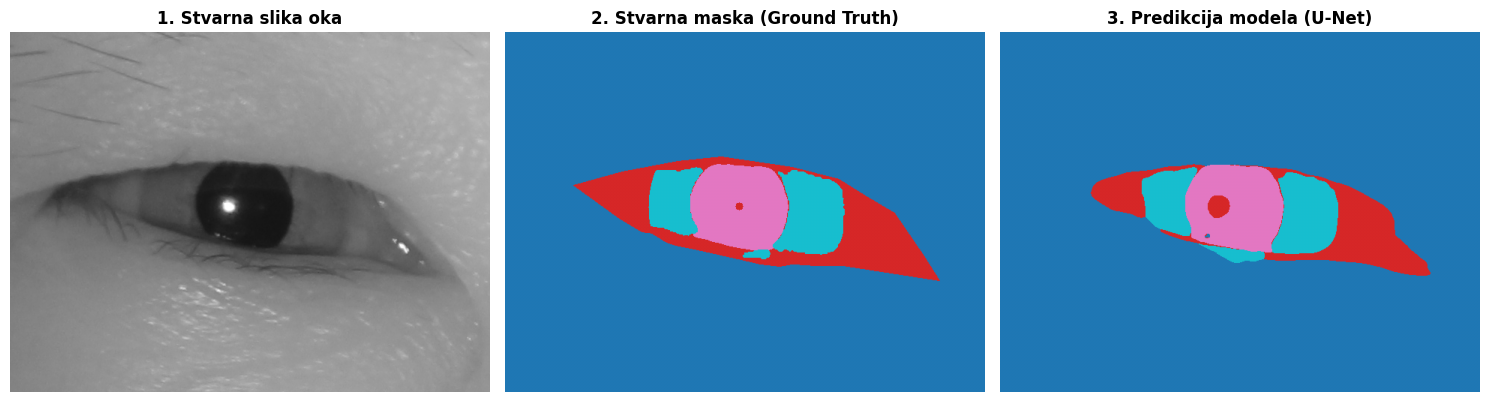

In [11]:
import torch
import matplotlib.pyplot as plt
import numpy as np
import random

def show_eye_prediction(model, loader, device):
    model.eval()

    # Dohvaćamo jedan batch iz validacijskog skupa
    images, masks = next(iter(loader))

    # Biramo nasumični indeks unutar batch-a (npr. od 0 do batch_size - 1)
    idx = random.randint(0, images.shape[0] - 1)

    img_tensor = images[idx].unsqueeze(0).to(device) # [1, 3, H, W]
    true_mask = masks[idx].numpy()                 # [H, W]
    original_img = images[idx].permute(1, 2, 0).cpu().numpy() # [H, W, 3]

    # Izvođenje predikcije
    with torch.no_grad():
        output = model(img_tensor)
        pred_mask = output.argmax(dim=1).squeeze(0).cpu().numpy() # [H, W]

    # Crtanje 3 usporedne slike
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    # 1. Stvarna slika oka
    axes[0].imshow(original_img)
    axes[0].set_title("1. Stvarna slika oka", fontsize=12, fontweight='bold')
    axes[0].axis('off')

    # 2. Stvarna maska
    im_true = axes[1].imshow(true_mask, cmap='tab10', vmin=0, vmax=3)
    axes[1].set_title("2. Stvarna maska (Ground Truth)", fontsize=12, fontweight='bold')
    axes[1].axis('off')

    # 3. Predikcija modela
    im_pred = axes[2].imshow(pred_mask, cmap='tab10', vmin=0, vmax=3)
    axes[2].set_title("3. Predikcija modela (U-Net)", fontsize=12, fontweight='bold')
    axes[2].axis('off')

    plt.tight_layout()
    plt.show()

# Pokretanje funkcije
show_eye_prediction(model, val_loader, DEVICE)

In [13]:
import os
import time
import torch
import segmentation_models_pytorch as smp

model_path = '/content/best_unet_eye_model.pth'

print("=" * 60)
print("ANALIZA MEMORIJSKOG OTIŚKA I VREMENA IZVOĐENJA")
print("=" * 60)

# 1. Memorijski otisak na disku (veličina datoteke)
file_size_mb = os.path.getsize(model_path) / (1024 * 1024)
print(f"Veličina datoteke modela na disku : {file_size_mb:.2f} MB")

# 2. Mjerenje vremena učitavanja modela
start_load = time.time()
# Inicijalizacija arhitekture i učitavanje težina u CPU memoriju
eval_model = smp.Unet(encoder_name="resnet34", encoder_weights=None, in_channels=3, classes=4)
eval_model.load_state_dict(torch.load(model_path, map_location='cpu'))
load_time = time.time() - start_load
print(f"Vrijeme učitavanja modela          : {load_time:.4f} sekundi")

# 3. Izračun memorijskog otiska u RAM/VRAM-u (težine i međuspremnici)
param_size = sum(p.numel() * p.element_size() for p in eval_model.parameters())
buffer_size = sum(b.numel() * b.element_size() for b in eval_model.buffers())
model_ram_mb = (param_size + buffer_size) / (1024 * 1024)
print(f"Memorijski otisak modela (RAM/VRAM): {model_ram_mb:.2f} MB")
print("-" * 60)

# 4. Funkcija za precizno mjerenje vremena inferencije po jednoj slici
def measure_inference_time(target_model, dataloader, device, num_runs=50):
    target_model.to(device)
    target_model.eval()

    # Uzimamo jednu uzorkovanu sliku iz testnog/validacijskog skupa
    images, _ = next(iter(dataloader))
    sample_image = images[0:1].to(device) # Oblik: [1, 3, H, W]

    # Zagrijavanje modela (warm-up) radi stabilizacije predmemorije
    with torch.no_grad():
        for _ in range(10):
            _ = target_model(sample_image)
            if device == 'cuda':
                torch.cuda.synchronize()

    # Mjerenje vremena izvođenja
    start_time = time.time()
    with torch.no_grad():
        for _ in range(num_runs):
            _ = target_model(sample_image)
            if device == 'cuda':
                torch.cuda.synchronize() # Osigurava točnu sinkronizaciju GPU-a
    end_time = time.time()

    # Vrijeme u milisekundama po jednoj slici
    avg_time_ms = ((end_time - start_time) / num_runs) * 1000
    return avg_time_ms

# Pokretanje testiranja na CPU-u
cpu_time = measure_inference_time(eval_model, test_loader, 'cpu', num_runs=30)
print(f"Prosječno vrijeme inferencije (CPU): {cpu_time:.2f} ms / slici")

# Pokretanje testiranja na GPU-u (ako je dostupan)
if torch.cuda.is_available():
    gpu_time = measure_inference_time(eval_model, test_loader, 'cuda', num_runs=50)
    print(f"Prosječno vrijeme inferencije (GPU): {gpu_time:.2f} ms / slici")
else:
    print("GPU nije dostupan na ovom okruženju.")

print("=" * 60)

ANALIZA MEMORIJSKOG OTIŚKA I VREMENA IZVOĐENJA
Veličina datoteke modela na disku : 93.39 MB
Vrijeme učitavanja modela          : 0.4255 sekundi
Memorijski otisak modela (RAM/VRAM): 93.29 MB
------------------------------------------------------------
💻 Prosječno vrijeme inferencije (CPU): 930.73 ms / slici
Prosječno vrijeme inferencije (GPU): 49.60 ms / slici
